<a href="https://colab.research.google.com/github/asthaa717/analisis-multivariat/blob/main/Analisis_multivariat_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Multidimensional Scaling

## Load Data & Standarize

In [ ]:
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np
iris = load_iris()
X = pd.DataFrame(iris.data, columns=iris.feature_names)
y = iris.target
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print(X.shape)


(150, 4)


Data Iris dimuat dengan 150 observasi dan 4 variabel (sepal length, sepal width, petal length, petal width). Output (150, 4) mengonfirmasi dimensi data. Variabel kemudian distandarisasi dengan StandardScaler (rata-rata 0, simpangan baku 1). Ini penting karena MDS berbasis jarak, sehingga variabel dengan skala besar akan mendominasi jarak jika tidak distandarisasi.

## Distance Matrix

In [ ]:
from sklearn.metrics import pairwise_distances
D = pairwise_distances(X_scaled, metric="euclidean")
print(D.shape)
print(np.round(D[:5, :5], 2))

(150, 150)
[[0.   1.18 0.85 1.1  0.26]
 [1.18 0.   0.52 0.43 1.39]
 [0.85 0.52 0.   0.28 0.99]
 [1.1  0.43 0.28 0.   1.25]
 [0.26 1.39 0.99 1.25 0.  ]]


Matriks jarak Euclidean berukuran 150 × 150 dihitung dari data terstandarisasi. Matriks ini simetris dan diagonalnya 0 (jarak objek ke dirinya sendiri). Dari 5 observasi pertama:

Jarak observasi 1 dan 5 sangat kecil (0,26), artinya keduanya sangat mirip.

Jarak observasi 1 dan 2 relatif besar (1,18), artinya keduanya cukup berbeda.

Jarak observasi 3 dan 4 kecil (0,28), artinya keduanya mirip.

Matriks inilah yang menjadi input semua metode MDS berikutnya.

## Classical MDS Manual

In [ ]:
n = D.shape[0]
J = (
 np.eye(n)
 - np.ones((n, n)) / n
)
B = (
 -0.5
 * J
 @ (D ** 2)
 @ J
)
eigenvalues, eigenvectors = (
 np.linalg.eigh(B)
)
idx = np.argsort(
 eigenvalues
)[::-1]
eigenvalues = eigenvalues[idx]
eigenvectors = eigenvectors[:, idx]
positive = eigenvalues > 0
eig_pos = eigenvalues[positive]
vec_pos = eigenvectors[:, positive]
coords_cmds = (
 vec_pos[:, :2]
 * np.sqrt(eig_pos[:2])
)
print(eigenvalues[:4])


[437.77467248 137.10457072  22.01353134   3.10722546]


1. Double centering: matriks centering J diterapkan pada kuadrat jarak untuk memperoleh matriks B = -½ J D² J.
2. Dekomposisi eigen dilakukan pada B, lalu eigenvalue diurutkan dari terbesar.
3. Koordinat diperoleh dari eigenvector × akar eigenvalue pada dua dimensi pertama

Interpretasi eigenvalue (437,77; 137,10; 22,01; 3,11):

- Total eigenvalue ≈ 600 (setara 150 × 4, sesuai total varians data terstandarisasi).

- Dimensi 1 menjelaskan ± 437,77/600 ≈ 72,9% dan dimensi 2 ± 137,10/600 ≈ 22,9%.

- Kumulatif dua dimensi ≈ 95,8%, sehingga representasi 2D sudah sangat baik dan hanya kehilangan sekitar 4% informasi.

- Dimensi 3 dan 4 sangat kecil kontribusinya, sehingga cukup 2 dimensi.

Hasilnya identik dengan PCA pada data terstandarisasi, karena Classical MDS dengan jarak Euclidean setara dengan PCA.

## Metric & Nonmetric MDS

In [ ]:
# metric
from sklearn.manifold import MDS
metric_mds = MDS(
 n_components=2,
 metric=True,
 dissimilarity="precomputed",
 random_state=42,
 n_init=4,
 max_iter=500
)
X_metric = metric_mds.fit_transform(D)
print("Metric Stress:", metric_mds.stress_)

Metric Stress: 235.41237809835042


Metric MDS (algoritma SMACOF) meminimalkan selisih antara jarak asli dan jarak pada peta 2D dengan n_init=4 dan max_iter=500. Nilai stress = 235,41 adalah raw stress (tidak dinormalisasi), sehingga nilainya tidak bisa langsung dibaca dengan kriteria Kruskal (misalnya <0,1 baik). Nilai ini lebih bermakna jika dibandingkan antarmodel, atau dinormalisasi terlebih dahulu. Karena skalanya bergantung pada banyaknya pasangan objek (150 objek menghasilkan sekitar 11.175 pasangan), angka 235 dalam konteks ini tidak otomatis berarti buruk.

In [ ]:
# nonmetric
nonmetric_mds = MDS(
 n_components=2,
 metric=False,
 dissimilarity="precomputed",
 random_state=42,
 n_init=4,
 max_iter=500,
 normalized_stress=False
)
X_nonmetric = nonmetric_mds.fit_transform(
 D, init=coords_cmds) # init dari Classical MDS
print("Nonmetric Stress:", nonmetric_mds.stress_)


Nonmetric Stress: 5.926804532696085


/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_mds.py:343: UserWarning: Explicit initial positions passed: performing only one init of the MDS instead of 4
  warnings.warn(


Nonmetric MDS hanya mempertahankan urutan peringkat (rank-order) jarak, bukan nilai jaraknya. Inisialisasi memakai koordinat Classical MDS agar solusi lebih stabil. Nilai stress = 5,93 jauh lebih kecil daripada metric MDS (235,41). Namun perlu hati-hati: kedua nilai ini tidak sepenuhnya sebanding, karena nonmetric MDS bekerja pada jarak yang telah ditransformasi monoton (disparities), sehingga skalanya berbeda. Secara umum, stress yang rendah menunjukkan urutan kemiripan antarobjek terjaga dengan baik di peta 2D.

## Visualisasi dan Interpretasi

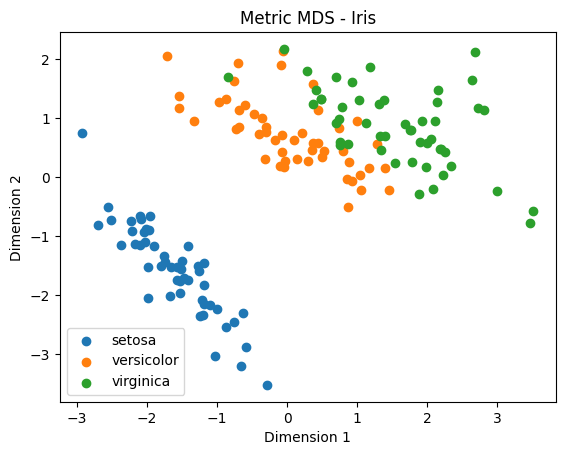

In [ ]:
# plot metric
import matplotlib.pyplot as plt
for cls in np.unique(y):
 mask = y == cls
 plt.scatter(X_metric[mask, 0],
 X_metric[mask, 1],
 label=iris.target_names[cls])
plt.xlabel("Dimension 1")
plt.ylabel("Dimension 2")
plt.title("Metric MDS - Iris")
plt.legend(); plt.show()


Plot menunjukkan sebaran 150 bunga Iris pada dua dimensi:

Setosa (biru) terpisah jelas di kiri bawah, jauh dari dua spesies lain. Ini menunjukkan karakteristik morfologinya sangat berbeda.
Versicolor (oranye) dan Virginica (hijau) berada di bagian atas dan saling tumpang tindih di area tengah. Artinya keduanya memiliki kemiripan morfologi yang tinggi dan lebih sulit dibedakan.
Virginica cenderung berada lebih ke kanan dan versicolor lebih ke tengah, sehingga ada kecenderungan pemisahan di sepanjang Dimensi 1.
Beberapa titik pencilan (misalnya setosa di kiri atas sekitar (-2,9; 0,7)) tampak menjauh dari kelompoknya.

sumbu pada MDS tidak memiliki makna absolut, karena orientasi bisa dirotasi atau dicerminkan. Yang bermakna adalah jarak relatif antartitik.